# 03. Logistic Regression Classifier

Baseline linear classification model for relationship compatibility.

In [2]:
# ============================================================
# Imports et configuration
# ============================================================
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, log_loss,
    precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

# Convention commune de l'équipe (identique dans src/data/preprocessing.py)
RANDOM_STATE = 42
N_SPLITS = 5

print("Bibliothèques chargées avec succès.")

Bibliothèques chargées avec succès.


In [5]:
# ============================================================
# Chemins du projet et import du code commun (dossier src/)
# ============================================================
def find_project_root():
    cwd = Path.cwd().resolve()
    for folder in [cwd, *cwd.parents]:
        if (folder / "src" / "data" / "preprocessing.py").exists() and (folder / "data" / "raw").exists():
            return folder
    raise FileNotFoundError(
        "Racine du projet introuvable (dossiers 'src' et 'data/raw' attendus). "
        "Lancez le notebook depuis le dossier du projet."
    )

ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_PATH = ROOT / "data" / "raw" / "cupid_algorithm_dataset.csv"
FIGURES_DIR = ROOT / "results" / "figures"
TABLES_DIR = ROOT / "results" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

try:
    from src.data.preprocessing import CupidDataPreprocessor
    from src.models.logistic_regression import CupidLogisticRegression
    from src.evluation.metrics import evaluate_classification_model, print_evaluation_summary
    from src.evluation.cross_validation import run_cross_validation
except ImportError as error:
    raise ImportError(
        "Import du code commun impossible. Installez les dépendances avec : "
        "pip install -r requirement.txt  (xgboost est requis par src/models)."
    ) from error

print("Racine du projet :", ROOT)
print("Données brutes   :", RAW_PATH)

Racine du projet : C:\Users\PC\Desktop\projet-FDD\DM_PROJECT
Données brutes   : C:\Users\PC\Desktop\projet-FDD\DM_PROJECT\data\raw\cupid_algorithm_dataset.csv


In [6]:
# ============================================================
# Prétraitement commun et découpage train / test
# ============================================================
preprocessor = CupidDataPreprocessor(test_size=0.2, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = preprocessor.prepare_train_test(str(RAW_PATH))

FEATURE_NAMES = list(preprocessor.feature_names)
CAT_NAMES = preprocessor.encoder.named_transformers_["cat"].get_feature_names_out(
    preprocessor.categorical_cols
).tolist()
NUM_NAMES = [name for name in FEATURE_NAMES if name not in CAT_NAMES]

# Contrôles de cohérence
for forbidden in ["compatibility_score", "relationship_longevity_months", "pair_id"]:
    assert forbidden not in FEATURE_NAMES, f"La colonne '{forbidden}' ne doit pas être utilisée."
assert X_train.shape[1] == X_test.shape[1] == len(FEATURE_NAMES)
assert not np.isnan(X_train).any() and not np.isnan(X_test).any(), "Valeurs manquantes détectées."

print(f"Train : {X_train.shape[0]:,} lignes x {X_train.shape[1]} variables ({y_train.mean():.2%} de compatibles)")
print(f"Test  : {X_test.shape[0]:,} lignes x {X_test.shape[1]} variables ({y_test.mean():.2%} de compatibles)")
print(f"\nVariables : {len(CAT_NAMES)} indicatrices (one-hot), {len(NUM_NAMES)} numériques")
print("Variables brutes :", len(preprocessor.numerical_raw_cols),
      "| variables construites :", len(NUM_NAMES) - len(preprocessor.numerical_raw_cols))

Train : 80,000 lignes x 73 variables (42.88% de compatibles)
Test  : 20,000 lignes x 73 variables (42.88% de compatibles)

Variables : 36 indicatrices (one-hot), 37 numériques
Variables brutes : 20 | variables construites : 17


In [7]:
# ============================================================
# Modèle de base (code commun de l'équipe)
# ============================================================
model = CupidLogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

metrics = evaluate_classification_model(model, X_test, y_test, "Logistic Regression")
print_evaluation_summary(metrics)


 Evaluation Metrics for: Logistic Regression
 Accuracy    : 0.7235
 Precision   : 0.7012
 Recall      : 0.6187
 F1-Score    : 0.6574
 ROC-AUC     : 0.7934
 Log Loss    : 0.5398
 Confusion Matrix:
[[9163 2261]
 [3270 5306]]



In [8]:
# ============================================================
# Fonction d'évaluation par seuil (réutilisée dans tout le notebook)
# ============================================================
def evaluate_proba(y_true, proba, threshold=0.5, name="modèle"):
    """Métriques de classification pour un seuil de décision donné."""
    pred = (proba >= threshold).astype(int)
    return {
        "Model": name,
        "Threshold": round(float(threshold), 3),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1-Score": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "LogLoss": log_loss(y_true, proba),
    }

proba_base = model.predict_proba(X_test)[:, 1]
results = [evaluate_proba(y_test, proba_base, 0.5, "Base (test)")]
display(pd.DataFrame(results).round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,LogLoss
0,Base (test),0.5,0.7234,0.7012,0.6187,0.6574,0.7934,0.7475,0.5398


                    precision    recall  f1-score   support

Non compatible (0)     0.7370    0.8021    0.7682     11424
    Compatible (1)     0.7012    0.6187    0.6574      8576

          accuracy                         0.7235     20000
         macro avg     0.7191    0.7104    0.7128     20000
      weighted avg     0.7216    0.7235    0.7207     20000

ROC-AUC train : 0.7973 | ROC-AUC test : 0.7934 | écart : 0.0039


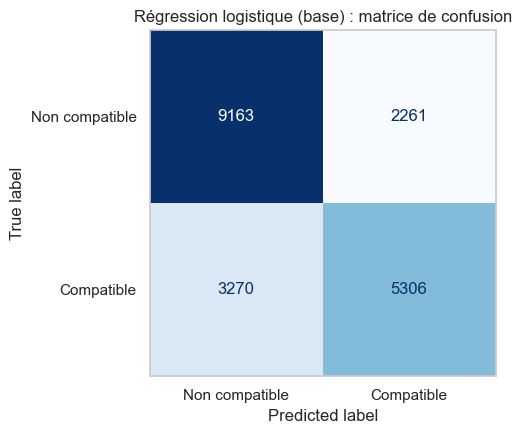

In [9]:
# ============================================================
# Rapport de classification, surapprentissage et matrice de confusion
# ============================================================
pred_base = (proba_base >= 0.5).astype(int)
print(classification_report(
    y_test, pred_base, target_names=["Non compatible (0)", "Compatible (1)"], digits=4
))

auc_train = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, proba_base)
print(f"ROC-AUC train : {auc_train:.4f} | ROC-AUC test : {auc_test:.4f} | écart : {auc_train - auc_test:.4f}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_base), display_labels=["Non compatible", "Compatible"]
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Régression logistique (base) : matrice de confusion")
ax.grid(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logistic_regression_confusion_matrix.png", dpi=150)
plt.show()